<a href="https://colab.research.google.com/github/prangyaparamita123/AML-LAB/blob/main/AMLlab2_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

y_name = input("Enter the name of the target variable y : ").strip()
y_input = input(f"Enter comma-separated numerical values for {y_name} (y): ")
y_vals = np.array([float(val) for val in y_input.split(",") if val.strip()])
num_data_points = len(y_vals)

num_features = int(input("\nHow many feature variables (x) do you want to enter? "))

x_data = {}
x_names = []
validation_passed = True

print("\nPlease enter comma-separated numerical values for each feature:")
for i in range(num_features):
    feat_name = input(f"Enter the name of feature x{i+1} : ").strip()
    x_names.append(feat_name)

    feat_input = input(f"Enter values for {feat_name} (x{i+1}): ")
    feat_vals = np.array([float(val) for val in feat_input.split(",") if val.strip()])

    if len(feat_vals) != num_data_points:
        print(f"\nError: '{feat_name}' has {len(feat_vals)} data points, but {y_name} has {num_data_points}.")
        validation_passed = False
        break

    x_data[f'x{i+1}'] = feat_vals

if not validation_passed:
    print("\nExecution stopped due to mismatched data point lengths.")
elif num_data_points < 2:
    print("\nError: Please enter at least 2 or more data points.")
else:
    data = pd.DataFrame(x_data)

    model = LinearRegression()
    model.fit(data, y_vals)
    predictions = model.predict(data)
    mse = mean_squared_error(y_vals, predictions)
    mae = mean_absolute_error(y_vals, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_vals, predictions)
    intercept = model.intercept_
    coefficients = model.coef_
    equation_terms = [f"({coef:.4f} * x{idx+1})" for idx, coef in enumerate(coefficients)]
    equation_str = f"y = {intercept:.4f} + " + " + ".join(equation_terms)

    print("Final Regression Equation:")
    print(equation_str)
    print(f"Intercept (b0): {intercept:.4f}")
    for idx, coef in enumerate(coefficients):
        print(f"Slope for {x_names[idx]} (b{idx+1}): {coef:.4f}")
    print(f"Mean Squared Error (MSE)       : {mse:.4f}")
    print(f"Mean Absolute Error (MAE)      : {mae:.4f}")
    print(f"Root Mean Squared Error (RMSE) : {rmse:.4f}")
    print(f"R² Score                       : {r2:.4f}")
    print()

    choice = input(f"Do you want to enter sample data for predicting {y_name}? (yes/no): ").strip().lower()

    if choice in ['yes', 'y']:
        try:
            print(f"\n--- Enter Values for Prediction ---")
            sample_dict = {}
            for idx, name in enumerate(x_names):
                val = float(input(f"Enter value for {name} (x{idx+1}): "))
                sample_dict[f'x{idx+1}'] = val

            sample_df = pd.DataFrame([sample_dict])
            predicted_val = model.predict(sample_df)[0]
            print(f">> Predicted {y_name} (y): {predicted_val:.4f}\n")
        except ValueError:
            print("Invalid input! Please enter numeric values.\n")

    elif choice in ['no', 'n']:
        print("Exiting prediction menu. Displaying graphs...\n")
    else:
        print("Invalid Input.\n")

    first_x_key = 'x1'
    first_x_vals = x_data[first_x_key]
    first_x_name = x_names[0]

Enter the name of the target variable y : final marks
Enter comma-separated numerical values for final marks (y): 45,60,75,90

How many feature variables (x) do you want to enter? 3

Please enter comma-separated numerical values for each feature:
Enter the name of feature x1 : study hours
Enter values for study hours (x1): 2,4,6,8
Enter the name of feature x2 : attendance(%)
Enter values for attendance(%) (x2): 60,75,80,85
Enter the name of feature x3 : assignments
Enter values for assignments (x3): 12,14,161,18
Final Regression Equation:
y = 30.0000 + (7.5000 * x1) + (0.0000 * x2) + (0.0000 * x3)
Intercept (b0): 30.0000
Slope for study hours (b1): 7.5000
Slope for attendance(%) (b2): 0.0000
Slope for assignments (b3): 0.0000
Mean Squared Error (MSE)       : 0.0000
Mean Absolute Error (MAE)      : 0.0000
Root Mean Squared Error (RMSE) : 0.0000
R² Score                       : 1.0000

Do you want to enter sample data for predicting final marks? (yes/no): no
Exiting prediction menu. Disp

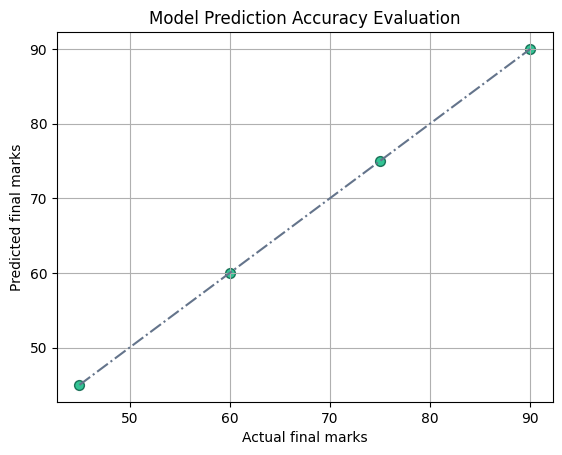

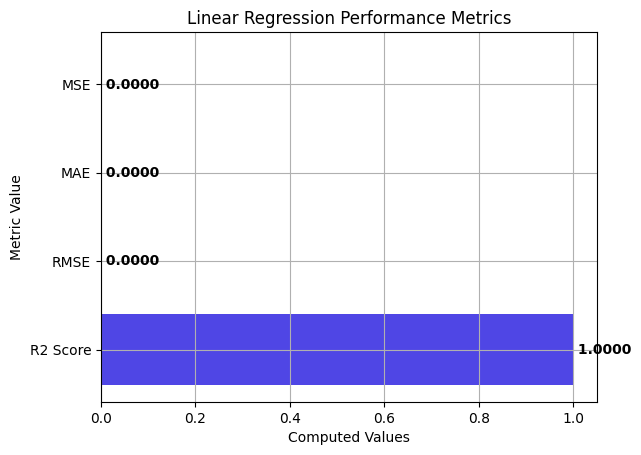

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.scatter(y_vals, predictions, color="#10b981", edgecolor="#065f46", linewidth=1, s=50, alpha=0.85)
min_val = min(float(np.min(y_vals)), float(np.min(predictions)))
max_val = max(float(np.max(y_vals)), float(np.max(predictions)))
plt.plot([min_val, max_val], [min_val, max_val], color="#64748b", linestyle="-.", linewidth=1.5)
plt.xlabel(f"Actual {y_name}")
plt.ylabel(f"Predicted {y_name}")
plt.title("Model Prediction Accuracy Evaluation")
plt.grid(True)
plt.show()

metrics_names = ["R2 Score", "RMSE", "MAE", "MSE"]
metrics_vals = [r2, rmse, mae, mse]
colors = ["#4f46e5", "#3b82f6", "#60a5fa", "#93c5fd"]
bars = plt.barh(metrics_names, metrics_vals, color=colors)
for bar in bars:
    width = bar.get_width()
    plt.annotate(f" {width:.4f}", xy=(width, bar.get_y() + bar.get_height() / 2), ha='left', va='center', fontweight='bold')
plt.xlabel("Computed Values")
plt.ylabel("Metric Value")
plt.title("Linear Regression Performance Metrics")
plt.grid(True)
plt.show()